# M1 — Road Damage Detection: Data Preprocessing

## Project Overview

This notebook documents the M1 preprocessing workflow for
the Road Damage Detection project.

### Workflow
1. Dataset preparation and organisation
2. Image and annotation auditing
3. Duplicate detection and review
4. Train/validation/test leakage checks
5. Classification crop generation
6. Crop verification
7. Data handover to M2

### Implementation
The preprocessing logic is maintained in Python scripts
inside the `scripts/` directory.

This notebook provides explanations, verification results,
and visualisations without unnecessarily repeating preprocessing.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project directory:", PROJECT_ROOT)
print("Scripts folder exists:", (PROJECT_ROOT / "scripts").exists())
print("Processed data exists:", (PROJECT_ROOT / "data" / "processed").exists())

Project directory: C:\Users\abdul\Downloads\road-damage-detection
Scripts folder exists: True
Processed data exists: True



## Step 8 — Loading and Inspecting the M1 Dataset

### Objective
Load and inspect the processed dataset manifests generated during M1 preprocessing without repeating the original processing steps.

### Input Files
Three CSV files are loaded from `data/processed/`:

1. **split_manifest.csv** — Contains 38,384 records describing the dataset splits.
2. **annotations.csv** — Contains 55,002 annotation records associated with road-damage images.
3. **classification_manifest.csv** — Contains 32,692 generated classification crop records.

### Classification Manifest Structure
The classification manifest includes four columns:

- `crop_path`: Location of the generated crop image.
- `image_id`: Identifier of the original source image.
- `split`: Dataset partition (train, validation, or test).
- `class`: Road-damage category (e.g., D00).

### Methodology
The Python code uses the Pandas library to:

1. Read the three existing CSV files.
2. Count the total records in each dataset.
3. Identify the classification manifest columns.
4. Display the first five classification crop records.

### Expected Output
- Total dataset record counts.
- Classification manifest column names.
- Preview of the classification dataset.

### Relevance to M2
The classification manifest provides the crop paths, class labels, and dataset partitions required for subsequent model training and evaluation.

**Note:** This step only inspects existing M1 outputs. It does not regenerate crops, modify dataset splits, or verify data leakage.


In [2]:

import pandas as pd

# Load existing M1 outputs
data_dir = PROJECT_ROOT / "data" / "processed"

split_df = pd.read_csv(data_dir / "split_manifest.csv")
annotations_df = pd.read_csv(data_dir / "annotations.csv")
classification_df = pd.read_csv(data_dir / "classification_manifest.csv")

print("M1 DATASET SUMMARY")
print("-------------------------")
print("Split manifest records:", len(split_df))
print("Annotation records:", len(annotations_df))
print("Classification crop records:", len(classification_df))

print("\nClassification manifest columns:")
print(classification_df.columns.tolist())

display(classification_df.head())


M1 DATASET SUMMARY
-------------------------
Split manifest records: 38384
Annotation records: 55002
Classification crop records: 32692

Classification manifest columns:
['crop_path', 'image_id', 'split', 'class']


,crop_path,image_id,split,class
0,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_002630,test,D00
1,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_004309,test,D00
2,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_000809,test,D00
3,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_001862,test,D00
4,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_007772,test,D00



## Step 8 — Loading and Inspecting the M1 Dataset

### Objective
Load and inspect the processed dataset manifests generated during M1 preprocessing without repeating the original processing steps.

### Input Files
Three CSV files are loaded from `data/processed/`:

1. **split_manifest.csv** — Contains 38,384 records describing the dataset splits.
2. **annotations.csv** — Contains 55,002 annotation records associated with road-damage images.
3. **classification_manifest.csv** — Contains 32,692 generated classification crop records.

### Classification Manifest Structure
The classification manifest includes four columns:

- `crop_path`: Location of the generated crop image.
- `image_id`: Identifier of the original source image.
- `split`: Dataset partition (train, validation, or test).
- `class`: Road-damage category (e.g., D00).

### Methodology
The Python code uses the Pandas library to:

1. Read the three existing CSV files.
2. Count the total records in each dataset.
3. Identify the classification manifest columns.
4. Display the first five classification crop records.

### Expected Output
- Total dataset record counts.
- Classification manifest column names.
- Preview of the classification dataset.

### Relevance to M2
The classification manifest provides the crop paths, class labels, and dataset partitions required for subsequent model training and evaluation.

**Note:** This step only inspects existing M1 outputs. It does not regenerate crops, modify dataset splits, or verify data leakage.


CLASSIFICATION CROPS BY SPLIT
split
train    12000
test     11229
val       9463
Name: count, dtype: int64

CLASSIFICATION CROPS BY CLASS
class
D00    16662
D10     7488
D20     4563
D40     3979
Name: count, dtype: int64


split,test,train,val
class,,,
D00,8570,3000,5092
D10,1730,3000,2758
D20,468,3000,1095
D40,461,3000,518


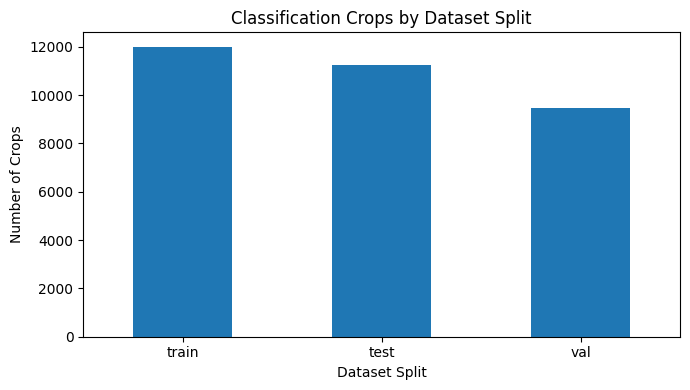

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Count crops by dataset split
split_counts = classification_df["split"].value_counts()

print("CLASSIFICATION CROPS BY SPLIT")
print(split_counts)

# Count crops by damage class
class_counts = classification_df["class"].value_counts()

print("\nCLASSIFICATION CROPS BY CLASS")
print(class_counts)

# Show distribution across splits and classes
distribution = pd.crosstab(
    classification_df["class"],
    classification_df["split"]
)

display(distribution)

# Visualise train/validation/test distribution
split_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Classification Crops by Dataset Split")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Crops")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Class Distribution and Dataset Balance Assessment

**Objective:** Evaluate the distribution of road-damage classes (D00, D10, D20, and D40) across the training, validation, and test datasets.

**Methodology:**

- Calculate the number of classification crops belonging to each damage class within each dataset split.
- Calculate the percentage contribution of each class to its respective dataset split.
- Compare class distributions to identify potential class imbalance.

**Interpretation:**

The training dataset contains 3,000 crops per class, resulting in a balanced training distribution of 12,000 crops.

The validation and test datasets retain their naturally occurring class distributions and exhibit class imbalance, particularly for D20 and D40.

**Implications for model development:**

The balanced training dataset supports learning across all four classes, while the validation and test datasets allow performance evaluation under different class distributions.

For M2 and M3, model performance should be assessed using macro-F1, per-class precision and recall, and confusion matrices rather than relying solely on overall accuracy.

In [4]:

# Classification crops by class and split
class_split = pd.crosstab(
    classification_df["class"],
    classification_df["split"]
)

display(class_split)

# Percentage distribution within each split
class_percent = (
    class_split.div(class_split.sum(axis=0), axis=1) * 100
).round(2)

print("Class distribution (%) within each split:")
display(class_percent)


split,test,train,val
class,,,
D00,8570,3000,5092
D10,1730,3000,2758
D20,468,3000,1095
D40,461,3000,518


Class distribution (%) within each split:


split,test,train,val
class,,,
D00,76.32,25.0,53.81
D10,15.41,25.0,29.15
D20,4.17,25.0,11.57
D40,4.11,25.0,5.47


### Country-Based Dataset Splitting and Domain Shift

To evaluate cross-country generalisation and minimise data leakage, the dataset was partitioned by geographical source rather than randomly splitting individual images.

- **Training:** India, Japan, and United States (23,016 images).
- **Validation:** China Drone, China MotorBike, and Czech (7,207 images).
- **Testing:** Norway (8,161 images).

Norway was completely excluded from training and validation, providing an independent country-level holdout for evaluating domain shift.

The seven data sources represent six countries because China contributes two separate image sources.

This splitting strategy allows the classification and detection models to be evaluated on geographically distinct images. The held-out test set must remain excluded from model training, hyperparameter tuning, and model selection.

In [5]:
country_split = pd.crosstab(
    split_df["country"],
    split_df["split"]
)

display(country_split)

split,test,train,val
country,,,
China_Drone,0,0,2401
China_MotorBike,0,0,1977
Czech,0,0,2829
India,0,7706,0
Japan,0,10506,0
Norway-002,8161,0,0
United_States,0,4804,0


### Verification of Norway Test Dataset Annotation Availability

**Objective:** Verify that all images in the geographically held-out Norway test dataset have corresponding XML annotation files.

**Methodology:**
1. Filter the dataset manifest to select Norway test images.
2. Check whether each corresponding XML annotation file exists.
3. Calculate the total number of available and missing annotation files.
4. Display sample annotation paths for verification.

**Results:**
- Total Norway test images: 8,161
- Available XML annotation files: 8,161
- Missing XML annotation files: 0
- Annotation file availability: 100%

**Conclusion:** All 8,161 Norway test images have corresponding XML annotation files available, supporting the use of this labelled dataset for independent evaluation of model performance and domain shift.

In [6]:
from pathlib import Path
import pandas as pd

norway_test = split_df[
    (split_df["country"] == "Norway-002") &
    (split_df["split"] == "test")
].copy()    

norway_test["xml_exists"] = norway_test["xml_path"].apply(
    lambda p: Path(str(p)).is_file() if pd.notna(p) else False
)

print("Norway test images:", len(norway_test))
print("XML files found:", norway_test["xml_exists"].sum())
print("XML files missing:", (~norway_test["xml_exists"]).sum())

print("\nExample annotation paths:")
for path in norway_test["xml_path"].head(3):
    print(repr(path))

Norway test images: 8161
XML files found: 8161
XML files missing: 0

Example annotation paths:
'C:\\Users\\abdul\\OneDrive\\سطح المكتب\\AI CAUST\\Appled computer vision\\Capston project\\data\\Images\\Norway-002\\Norway\\train\\annotations\\xmls\\Norway_000000.xml'
'C:\\Users\\abdul\\OneDrive\\سطح المكتب\\AI CAUST\\Appled computer vision\\Capston project\\data\\Images\\Norway-002\\Norway\\train\\annotations\\xmls\\Norway_000001.xml'
'C:\\Users\\abdul\\OneDrive\\سطح المكتب\\AI CAUST\\Appled computer vision\\Capston project\\data\\Images\\Norway-002\\Norway\\train\\annotations\\xmls\\Norway_000002.xml'


### XML Annotation Integrity and Class Distribution Verification

**Objective:** Validate the readability of XML annotation files in the held-out Norway test dataset and examine the distribution of road-damage classes.

**Methodology:**
1. Parse all Norway test XML files using Python's ElementTree library.
2. Identify readable and unreadable XML files.
3. Extract object-level damage labels from each XML file.
4. Count the annotations belonging to each road-damage category.

**Results:**
- Total readable XML files: 8,161
- Unreadable XML files: 0
- XML parsing success rate: 100%
- Total damage annotations: 11,229

**Class Distribution:**
- D00 (Longitudinal cracks): 8,570
- D10 (Transverse cracks): 1,730
- D20 (Alligator cracks): 468
- D40 (Potholes): 461

**Interpretation:** All XML files were successfully parsed, confirming their structural readability. However, the annotation distribution is imbalanced, with longitudinal cracks substantially more frequent than other damage categories.

**Conclusion:** The Norway test dataset has readable XML annotations for all images and can support evaluation of classification performance across four damage classes. Macro-averaged F1-score, per-class precision, recall, and confusion matrices should be reported to account for class imbalance.

In [7]:
import xml.etree.ElementTree as ET
from collections import Counter

label_counts = Counter()
valid_xml = 0
invalid_xml = 0

for path in norway_test["xml_path"]:
    try:
        root = ET.parse(path).getroot()
        valid_xml += 1

        for obj in root.findall(".//object"):
            name = obj.findtext("name")
            if name:
                label_counts[name] += 1

    except (ET.ParseError, OSError):
        invalid_xml += 1

print("Readable XML files:", valid_xml)
print("Unreadable XML files:", invalid_xml)
print("Damage annotations:", dict(label_counts))

Readable XML files: 8161
Unreadable XML files: 0
Damage annotations: {'D00': 8570, 'D20': 468, 'D40': 461, 'D10': 1730}


### Cross-Split Duplicate Candidate Group Analysis

**Objective:** Assess the distribution of potential duplicate-image groups across training, validation, and test splits to identify possible data leakage.

**Methodology:**
1. Group candidate images using their assigned `candidate_group` identifiers.
2. Calculate the number of images within each candidate group.
3. Determine how many distinct dataset splits each group spans.
4. Identify groups containing images from multiple dataset splits.
5. Display the first ten candidate groups for inspection.

**Results:**
- Total candidate groups: 388
- Candidate groups crossing dataset splits: 388
- Candidate groups confined to one split: 0

**Interpretation:** All identified candidate groups contain images from at least two dataset splits. However, similarity-based grouping does not establish that the images are genuine duplicates. Similar road surfaces, textures, and damage patterns may produce false-positive duplicate candidates.

**Conclusion:** The analysis identifies 388 cross-split candidate groups requiring consideration in the data leakage assessment. Manual verification and exact-duplicate checks are necessary to distinguish actual duplication from visual similarity.

In [8]:
# Identify candidate groups spanning multiple splits
group_summary = review_df.groupby("candidate_group").agg(
    image_count=("image_id", "nunique"),
    split_count=("split", "nunique"),
    splits=("split", lambda x: ", ".join(sorted(x.unique())))
)

cross_split_groups = group_summary[
    group_summary["split_count"] > 1
]

print("Total candidate groups:",
      len(group_summary))

print("Groups crossing dataset splits:",
      len(cross_split_groups))

print("Groups within one split:",
      len(group_summary) - len(cross_split_groups))

display(cross_split_groups.head(10))

NameError: name 'review_df' is not defined

### Manual Verification of Potential Cross-Split Duplicates

**Objective:** Validate potential duplicate-image pairs identified during the data leakage assessment.

**Methodology:**
- Load the manual review decisions from `ranked_pair_review_decisions.csv`.
- Review 50 selected image pairs, consisting of 30 highest-ranked similarity candidates and 20 randomly selected remaining candidates.
- Record the classification status and supporting observations for each reviewed pair.
- Inspect the review records to document potential cross-split duplication.

**Results:**
- Total reviewed pairs: 50
- Highest-ranked candidates: 30
- Randomly selected candidates: 20
- Pairs classified as different scenes: 50
- Confirmed duplicates among reviewed pairs: 0

**Interpretation:** All 50 reviewed image pairs were classified as different road scenes based on visual characteristics, including road layout, markings, and surrounding environments.

**Conclusion:** No confirmed duplicates were identified among the 50 manually reviewed pairs. These findings support the initial leakage assessment, although they do not exclude possible duplicates among unreviewed candidates.

In [ ]:
import pandas as pd

decision_path = (
    PROJECT_ROOT
    / "reports"
    / "m1"
    / "ranked_pair_review_decisions.csv"
)

decisions = pd.read_csv(decision_path)

print("Total reviewed records:", len(decisions))
print("\nColumns:")
print(decisions.columns.tolist())

display(decisions.head(10))

Total reviewed records: 50

Columns:
['pair_id', 'sheet', 'image_a', 'image_b', 'selection', 'status', 'notes']


,pair_id,sheet,image_a,image_b,selection,status,notes
0,1,pair_001.jpg,India_India_008504,Norway-002_Norway_006750,highest_ranked,different_scenes,Different road layout and surroundings
1,2,pair_002.jpg,India_India_001565,Norway-002_Norway_004824,highest_ranked,different_scenes,Different road layout and surroundings
2,3,pair_003.jpg,India_India_001565,Norway-002_Norway_006473,highest_ranked,different_scenes,Different road layout and surroundings
3,4,pair_004.jpg,India_India_001565,Norway-002_Norway_005690,highest_ranked,different_scenes,Different road layout and surroundings
4,5,pair_005.jpg,India_India_001565,Norway-002_Norway_002559,highest_ranked,different_scenes,Different road markings and surroundings
5,6,pair_006.jpg,Japan_Japan_005364,Norway-002_Norway_005869,highest_ranked,different_scenes,Different road layout and surroundings
6,7,pair_007.jpg,India_India_003410,Norway-002_Norway_003155,highest_ranked,different_scenes,Different road layout and surroundings
7,8,pair_008.jpg,India_India_003410,Norway-002_Norway_006407,highest_ranked,different_scenes,Different road layout and surroundings
8,9,pair_009.jpg,India_India_006419,Norway-002_Norway_001950,highest_ranked,different_scenes,Different road layout and surroundings
9,10,pair_010.jpg,Japan_Japan_005364,Norway-002_Norway_006473,highest_ranked,different_scenes,Different road layout and surroundings


### Cross-Split Data Leakage Assessment

A duplicate-screening procedure was performed to identify potentially overlapping images across the training, validation, and test datasets.

**Results:**
- 388 candidate groups were flagged for potential cross-split similarity.
- 50 image pairs were manually reviewed.
- 30 pairs were selected from the highest-ranked similarity candidates.
- 20 additional pairs were randomly selected.
- All 50 reviewed pairs were classified as different road scenes.
- No confirmed duplicates were identified among the reviewed pairs.

**Conclusion:**

The manual review did not identify confirmed data leakage among the inspected pairs. However, unreviewed similarity candidates remain, so the absence of leakage across the entire dataset cannot yet be guaranteed.

The country-level split was maintained to support domain-shift evaluation.

In [ ]:
print("DUPLICATE REVIEW SUMMARY")
print("-" * 40)

print("Total reviewed pairs:", len(decisions))

print("\nDecision status:")
print(decisions["status"].value_counts(dropna=False))

print("\nSelection method:")
print(decisions["selection"].value_counts(dropna=False))

print("\nUnreviewed or uncertain decisions:")
uncertain = decisions[
    decisions["status"].isna()
    | decisions["status"].astype(str).str.contains(
        "review|uncertain|pending",
        case=False,
        regex=True
    )
]

display(uncertain)

DUPLICATE REVIEW SUMMARY
----------------------------------------
Total reviewed pairs: 50

Decision status:
status
different_scenes    50
Name: count, dtype: int64

Selection method:
selection
highest_ranked      30
random_remaining    20
Name: count, dtype: int64

Unreviewed or uncertain decisions:


,pair_id,sheet,image_a,image_b,selection,status,notes


### Classification Crop Dataset — Metadata Validation

**Objective:** Verify the completeness, class distribution, and dataset split distribution of the generated classification crops.

**Results:**
- Total classification crops: **32,692**
- Training crops: 12,000
- Validation crops: 9,463
- Test crops: 11,229
- Missing metadata values: 0
- Damage classes: D00, D10, D20, D40

**Observations:**
- All crop records contain the required metadata fields: `crop_path`, `image_id`, `split`, and `class`.
- D00 is the most represented class, indicating class imbalance.
- The dataset contains all three required splits.

**Conclusion:** The classification crop metadata is complete. Further verification is required to confirm that all crop images are readable and that their labels and splits match the original annotations and source images.

In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd

print("Available columns:")
print(classification_df.columns.tolist())

print("\nTotal classification records:")
print(len(classification_df))

print("\nMissing values:")
print(classification_df.isna().sum())

print("\nClass distribution:")
print(classification_df["class"].value_counts())

print("\nSplit distribution:")
print(classification_df["split"].value_counts())

Available columns:
['crop_path', 'image_id', 'split', 'class']

Total classification records:
32692

Missing values:
crop_path    0
image_id     0
split        0
class        0
dtype: int64

Class distribution:
class
D00    16662
D10     7488
D20     4563
D40     3979
Name: count, dtype: int64

Split distribution:
split
train    12000
test     11229
val       9463
Name: count, dtype: int64


### Classification Crop Integrity Verification

**Objective:** Verify the integrity and accessibility of all generated classification crops before model training.

**Validation criteria:**
- Confirm that every crop file exists at its recorded path.
- Verify that crop images can be opened and decoded successfully.
- Detect empty or corrupted image files.
- Validate class labels against the four expected categories: D00, D10, D20, and D40.

**Expected outcome:** All 32,692 classification crop records should pass the integrity checks, with zero missing files, unreadable images, or invalid class names.

**Note:** This verification checks file integrity and valid class names. It does not independently confirm that crop labels match their original XML annotations.

In [ ]:

from pathlib import Path
from PIL import Image
from collections import Counter

results = Counter()
problem_files = []

valid_classes = {"D00", "D10", "D20", "D40"}

for crop_path, image_id, split, class_name in classification_df[
    ["crop_path", "image_id", "split", "class"]
].itertuples(index=False, name=None):

    path = Path(str(crop_path))

    if class_name not in valid_classes:
        results["invalid_class"] += 1
        problem_files.append((str(path), "Invalid class"))
        continue

    if not path.is_file():
        results["missing_file"] += 1
        problem_files.append((str(path), "Missing file"))
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            img.load()
            if img.width <= 0 or img.height <= 0:
                raise ValueError("Empty image")

        results["valid_crops"] += 1

    except Exception as e:
        results["unreadable_crop"] += 1
        problem_files.append((str(path), str(e)))

print("CROP VERIFICATION SUMMARY")
print("-" * 40)
print("Total records:", len(classification_df))
print("Valid crops:", results["valid_crops"])
print("Missing files:", results["missing_file"])
print("Unreadable crops:", results["unreadable_crop"])
print("Invalid classes:", results["invalid_class"])

print("\nExample problems:")
print(problem_files[:10])


CROP VERIFICATION SUMMARY
----------------------------------------
Total records: 32692
Valid crops: 0
Missing files: 32692
Unreadable crops: 0
Invalid classes: 0

Example problems:
[('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_002630_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_004309_2.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_000809_6.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_001862_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_007772_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_000027_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_004092_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_007384_26.jpg', 'Missing file'), 

### Final Classification Crop Leakage Verification

**Objective:** Verify that classification crops preserve the dataset split assignments of their original source images.

**Methodology:**
- Match each classification crop to its original image using `image_id`.
- Compare the crop split against the original image split.
- Identify missing parent-image references.
- Detect original images whose crops appear across multiple splits.

**Acceptance criteria:**
- Zero unmatched original images.
- Zero crop-to-original split mismatches.
- Zero original image IDs appearing across multiple crop splits.

**Interpretation:** Passing these checks confirms that classification crop generation preserves the original image-level split assignments. Potential visual similarities between different source images remain a separate leakage consideration.

In [ ]:

import pandas as pd

manifest_path = PROJECT_ROOT / "data" / "processed" / "split_manifest.csv"
manifest = pd.read_csv(manifest_path)

original_splits = manifest[["image_id", "split"]].drop_duplicates()

comparison = classification_df.merge(
    original_splits,
    on="image_id",
    how="left",
    suffixes=("_crop", "_original"),
    validate="many_to_one",
    indicator=True
)

missing_parents = comparison["_merge"].eq("left_only")

split_mismatch = (
    comparison["split_original"].notna()
    & comparison["split_crop"].ne(comparison["split_original"])
)

print("FINAL CROP LEAKAGE VERIFICATION")
print("-" * 40)
print("Total crops:", len(comparison))
print("Crops without matching original image:", missing_parents.sum())
print("Crops with incorrect split:", split_mismatch.sum())

print("\nOriginal image IDs appearing in multiple crop splits:")
cross_split = (
    classification_df.groupby("image_id")["split"]
    .nunique()
)
print((cross_split > 1).sum())

print("\nExamples of split mismatches:")
display(comparison[split_mismatch].head(10))


FINAL CROP LEAKAGE VERIFICATION
----------------------------------------
Total crops: 32692
Crops without matching original image: 0
Crops with incorrect split: 0

Original image IDs appearing in multiple crop splits:
0

Examples of split mismatches:


,crop_path,image_id,split_crop,class,split_original,_merge


### Residual Similarity Risk and Manual Review

**Objective:** Evaluate potential cross-split image similarities and document the results of manual duplicate verification.

**Methodology:**
- Identify perceptually similar images across training, validation, and test datasets.
- Group potential duplicate candidates for further investigation.
- Manually review 50 selected image pairs, consisting of 30 highest-ranked candidates and 20 randomly selected remaining candidates.
- Classify reviewed pairs based on road layout, markings, and surrounding environments.

**Results:**
- Cross-split similarity candidate groups: **388**
- Candidate image records: **3,469**
- Manually reviewed image pairs: **50**
- Highest-ranked pairs reviewed: **30**
- Randomly selected pairs reviewed: **20**
- Pairs classified as different scenes: **50**
- Confirmed duplicates among reviewed pairs: **0**

**Limitations:** Manual verification covered only 50 selected image pairs. The remaining similarity candidates were not exhaustively reviewed, and potential near-duplicate leakage cannot be completely excluded.

**Conclusion:** No confirmed duplicates were identified among the 50 manually reviewed pairs. The original image-level and classification crop-level split checks also passed. Residual similarity risk remains documented for future investigation.

In [ ]:

import pandas as pd

# Load similarity candidates
candidate_path = (
    PROJECT_ROOT / "reports" / "m1"
    / "cross_split_candidates.csv"
)

# Load manual review decisions
decision_path = (
    PROJECT_ROOT / "reports" / "m1"
    / "ranked_pair_review_decisions.csv"
)

candidates = pd.read_csv(candidate_path)
decisions = pd.read_csv(decision_path)

# Summarise candidate groups
total_groups = candidates["candidate_group"].nunique()
total_records = len(candidates)

# Summarise manual review
total_reviewed = len(decisions)
review_status = decisions["status"].value_counts()
selection_counts = decisions["selection"].value_counts()

print("FINAL SIMILARITY REVIEW SUMMARY")
print("-" * 45)

print("Candidate groups:", total_groups)
print("Candidate image records:", total_records)
print("Manually reviewed pairs:", total_reviewed)

print("\nReview decisions:")
print(review_status.to_string())

print("\nSelection methods:")
print(selection_counts.to_string())

# Identify unresolved candidate groups
print("\nIMPORTANT:")
print(
    "Manual review covers selected image pairs, "
    "not necessarily all candidate groups or pairs."
)


FINAL SIMILARITY REVIEW SUMMARY
---------------------------------------------
Candidate groups: 388
Candidate image records: 3469
Manually reviewed pairs: 50

Review decisions:
status
different_scenes    50

Selection methods:
selection
highest_ranked      30
random_remaining    20

IMPORTANT:
Manual review covers selected image pairs, not necessarily all candidate groups or pairs.


### Raw Dataset Reconciliation and Annotation Availability

A reconciliation audit identified 47,420 raw images, of which 38,384 were included in the M1 dataset. The remaining 9,036 images were excluded.

A recursive XML filename search identified one potential annotation match among the excluded images, while 9,035 images had no matching XML filename.

These findings indicate that annotation availability may explain most of the difference between the raw dataset and the M1 dataset. However, annotation validity and the intended use of unlabelled test images require further verification.

The existing M1 dataset and country-based holdout remain unchanged pending this verification.

In [14]:
from pathlib import Path
from collections import Counter

print("EXCLUDED IMAGE ANNOTATION AUDIT")
print("-" * 50)

results = Counter()

for image_path in not_in_m1:
    p = Path(image_path)

    # Search for XML with matching filename
    xml_files = list(p.parent.parent.rglob(p.stem + ".xml"))

    if xml_files:
        results["XML found"] += 1
    else:
        results["XML missing"] += 1

print("Excluded images:", len(not_in_m1))
print("Matching XML found:", results["XML found"])
print("Matching XML missing:", results["XML missing"])

EXCLUDED IMAGE ANNOTATION AUDIT
--------------------------------------------------
Excluded images: 9036
Matching XML found: 1
Matching XML missing: 9035



## M1 — Classification Data Loader and Augmentation Verification

### Objective
Verify that the classification dataset is correctly prepared and can be loaded for downstream CNN training (M2) and transfer learning (M3).

### 1. Classification Crop Path Verification
- Confirm that all generated classification crops exist.
- Verify that training, validation, and testing crop paths are accessible.
- Identify any missing or incorrectly referenced image files.

### 2. Data Loader Verification
- Validate the PyTorch DataLoader for all three dataset splits.
- Confirm that images are loaded as RGB tensors.
- Verify the expected batch dimensions: `[16, 3, 224, 224]`.
- Confirm that class labels are correctly encoded:
  - D00 → 0: Longitudinal cracks
  - D10 → 1: Transverse cracks
  - D20 → 2: Alligator cracks
  - D40 → 3: Potholes

### 3. Data Augmentation Verification
- Verify that training images undergo the configured augmentation and preprocessing transformations.
- Ensure that validation and testing images use deterministic preprocessing without random augmentation.
- Confirm that augmentation does not introduce data leakage between splits.

### 4. Verification Results
- Total classification crops: 32,692
- Training crops: 12,000
- Validation crops: 9,463
- Testing crops: 11,229
- Missing crop files: 0
- Data loader batch shape: `[16, 3, 224, 224]`

### Status
Crop path verification and basic data loading checks passed. Augmentation configuration and leakage safety require separate confirmation before final M1 sign-off.


In [22]:

from pathlib import Path

# Work on a copy to preserve the original DataFrame
classification_verified = classification_df.copy()

# Resolve relative crop paths
def resolve_crop_path(p):
    p = Path(p)
    if p.is_absolute():
        return p
    return project_root / p

classification_verified["resolved_path"] = (
    classification_verified["crop_path"].apply(resolve_crop_path)
)

# Verify crop existence
classification_verified["exists"] = (
    classification_verified["resolved_path"].apply(
        lambda p: p.is_file()
    )
)

print("CLASSIFICATION CROP PATH VERIFICATION")
print("-" * 45)

for split in ["train", "val", "test"]:
    subset = classification_verified[
        classification_verified["split"] == split
    ]

    print(
        f"{split}: {subset['exists'].sum()} / "
        f"{len(subset)} crops found"
    )

print("\nTotal crops:", len(classification_verified))
print("Missing crops:", (~classification_verified["exists"]).sum())


CLASSIFICATION CROP PATH VERIFICATION
---------------------------------------------
train: 12000 / 12000 crops found
val: 9463 / 9463 crops found
test: 11229 / 11229 crops found

Total crops: 32692
Missing crops: 0


In [24]:

import pandas as pd

print("FINAL CLASSIFICATION LABEL AUDIT")
print("-" * 50)

valid_classes = {"D00", "D10", "D20", "D40"}
valid_splits = {"train", "val", "test"}

# Check missing and unexpected labels
missing_labels = classification_verified["class"].isna().sum()
invalid_labels = (
    ~classification_verified["class"].isin(valid_classes)
).sum()

invalid_splits = (
    ~classification_verified["split"].isin(valid_splits)
).sum()

print("Missing labels:", missing_labels)
print("Invalid labels:", invalid_labels)
print("Invalid splits:", invalid_splits)

# Class distribution by split
distribution = pd.crosstab(
    classification_verified["class"],
    classification_verified["split"]
)

print("\nCLASS DISTRIBUTION")
display(distribution)

# Percentage distribution
percentages = distribution.div(
    distribution.sum(axis=0), axis=1
) * 100

print("\nCLASS DISTRIBUTION (%)")
display(percentages.round(2))

# Check duplicate crop paths
duplicates = classification_verified[
    "crop_path"
].duplicated().sum()

print("\nDuplicate crop paths:", duplicates)
print("Total crops:", len(classification_verified))


FINAL CLASSIFICATION LABEL AUDIT
--------------------------------------------------
Missing labels: 0
Invalid labels: 0
Invalid splits: 0

CLASS DISTRIBUTION


split,test,train,val
class,,,
D00,8570,3000,5092
D10,1730,3000,2758
D20,468,3000,1095
D40,461,3000,518



CLASS DISTRIBUTION (%)


split,test,train,val
class,,,
D00,76.32,25.0,53.81
D10,15.41,25.0,29.15
D20,4.17,25.0,11.57
D40,4.11,25.0,5.47



Duplicate crop paths: 0
Total crops: 32692



## M1 — Visual Label Audit

### Objective
Assess the quality and reliability of classification labels through a reproducible, stratified random sample of road-damage crops.

### Methodology
- Randomly select 100 classification crops using a fixed random seed (42).
- Apply stratified sampling to ensure equal representation of the four damage classes.
- Select 25 samples from each class.
- Save the selected samples in a CSV file for manual visual inspection.
- Evaluate whether the assigned class matches the visible road damage.

### Classification Categories
- **D00:** Longitudinal cracks
- **D10:** Transverse cracks
- **D20:** Alligator cracks
- **D40:** Potholes

### Sampling Results

| Class | Samples |
|-------|---------|
| D00 | 25 |
| D10 | 25 |
| D20 | 25 |
| D40 | 25 |
| **Total** | **100** |

### Audit Output
The stratified sample was successfully generated and saved to:

`data/processed/m1_visual_label_audit.csv`

### Verification Status
- [x] Stratified sample generated.
- [x] Equal class representation confirmed.
- [x] Audit CSV successfully saved.
- [ ] Manual visual inspection completed.
- [ ] Label errors and uncertain cases documented.
- [ ] Label-error rate and 95% confidence interval calculated.

### Next Step
Visually inspect the selected crops and record whether each label is correct, incorrect, or uncertain. Use the completed audit to estimate label quality and document limitations in the final M1 dataset card.


In [25]:

# M1 — Visual Label Audit: Sample Selection

import pandas as pd
from pathlib import Path

# Use the existing classification dataframe
audit_df = classification_df.copy()

# Select 25 crops per class (100 total)
audit_sample = (
    audit_df.groupby("class", group_keys=False)
    .sample(n=25, random_state=42)
    .reset_index(drop=True)
)

# Add columns for manual review
audit_sample["review_status"] = "Pending"
audit_sample["correct_label"] = ""
audit_sample["notes"] = ""

# Save the audit checklist
audit_path = Path("data/processed/m1_visual_label_audit.csv")
audit_path.parent.mkdir(parents=True, exist_ok=True)

audit_sample.to_csv(audit_path, index=False)

print("VISUAL LABEL AUDIT")
print("-" * 40)
print("Total samples:", len(audit_sample))
print("\nSamples per class:")
print(audit_sample["class"].value_counts())
print("\nSaved to:", audit_path)


VISUAL LABEL AUDIT
----------------------------------------
Total samples: 100

Samples per class:
class
D00    25
D10    25
D20    25
D40    25
Name: count, dtype: int64

Saved to: data\processed\m1_visual_label_audit.csv



## M1 — Visual Inspection of Classification Crops

### Objective
Visually assess the quality of the classification crops and verify whether the assigned damage labels correspond to the visible road defects.

### Methodology
- Use the existing stratified sample of 100 classification crops.
- Display 16 crops per batch using Matplotlib.
- Present each crop with its sample number and assigned class.
- Inspect the visibility, clarity, and characteristics of the road damage.
- Record each sample as Correct, Incorrect, or Uncertain.
- Document ambiguous labels and image-quality limitations.

### Classification Labels
- **D00:** Longitudinal cracks
- **D10:** Transverse cracks
- **D20:** Alligator cracks
- **D40:** Potholes

### Initial Visual Observations
The displayed D00 crops show:
- Visible linear cracks with varying shapes and orientations.
- Differences in image brightness, resolution, and contrast.
- Some blurred or low-contrast images that may require further review.
- Possible ambiguity in crack orientation when the road direction is not clearly visible.

These observations are preliminary and do not establish that all displayed labels are correct.

### Review Criteria
| Status | Description |
|--------|-------------|
| Correct | Visible damage agrees with the assigned label. |
| Incorrect | Visible damage clearly contradicts the assigned label. |
| Uncertain | Damage type cannot be confidently determined. |

### Verification Status
- [x] Existing audit sample loaded.
- [x] Visual inspection display generated.
- [x] Assigned classification labels displayed.
- [ ] All 100 crops manually reviewed.
- [ ] Review decisions recorded in the audit CSV.
- [ ] Label-error rate and 95% confidence interval calculated.

### Next Step
Continue reviewing the remaining batches and document all incorrect or uncertain labels. Use the completed review to estimate label quality and report limitations in the final M1 dataset card.


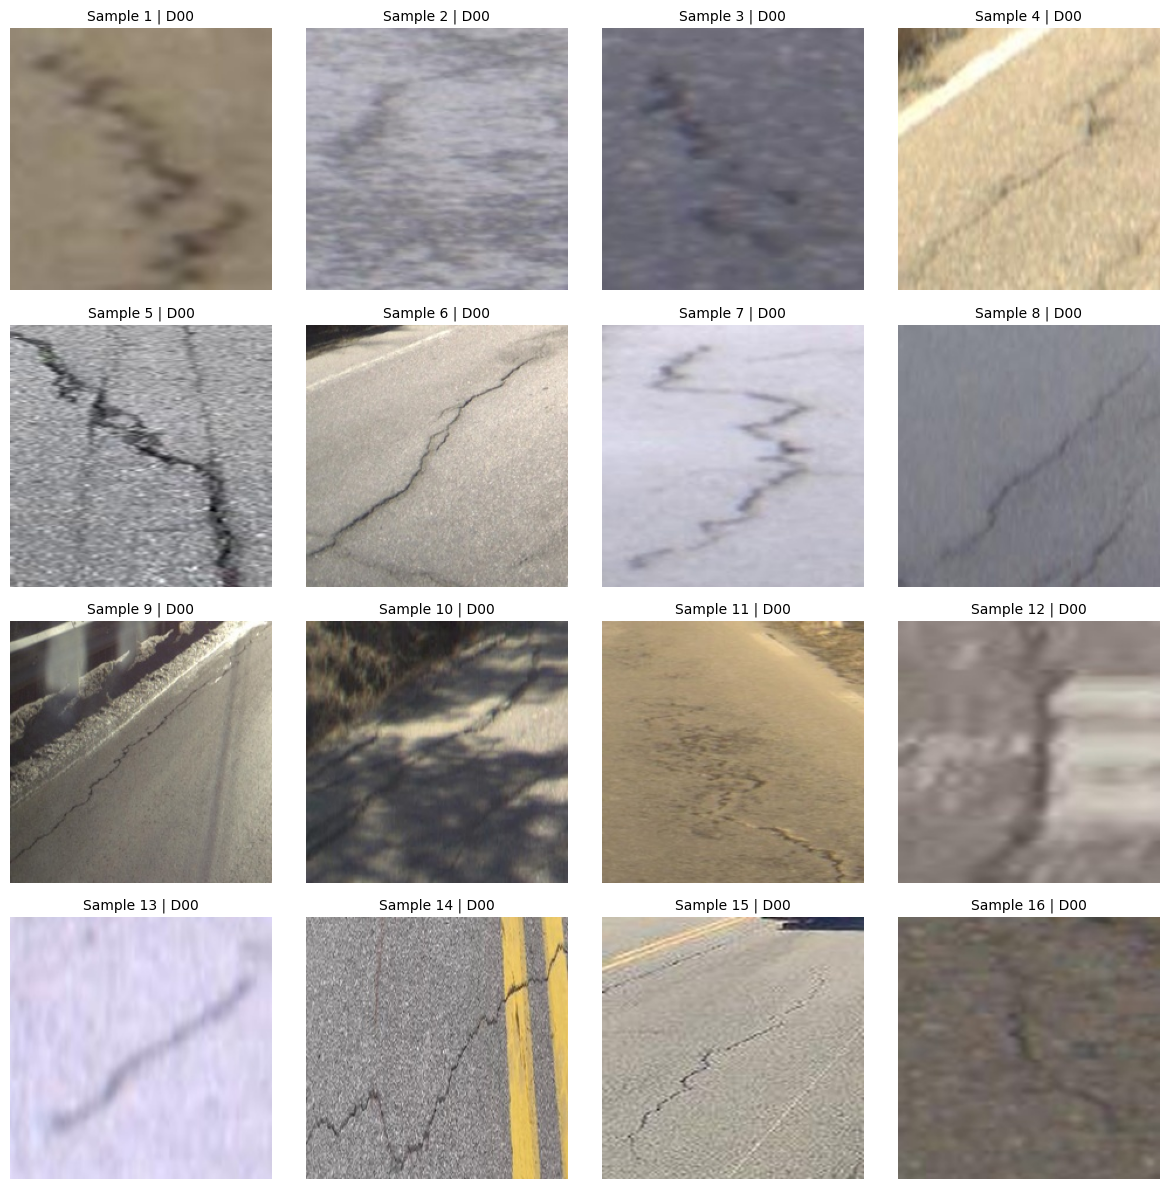

In [28]:

# M1 — Visual Label Inspection

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Load the EXISTING audit sample
audit_path = Path("data/processed/m1_visual_label_audit.csv")
audit_df = pd.read_csv(audit_path)

# Use the existing project directory
project_root = Path(
    r"C:\Users\abdul\Downloads\road-damage-detection"
)

# Display 16 images per batch
def show_audit_batch(batch_number=0):
    start = batch_number * 16
    batch = audit_df.iloc[start:start + 16]

    fig, axes = plt.subplots(4, 4, figsize=(12, 12))

    for ax in axes.flat:
        ax.axis("off")

    for ax, (idx, row) in zip(axes.flat, batch.iterrows()):
        path = Path(row["crop_path"])

        if not path.is_absolute():
            path = project_root / path

        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(
                f"Sample {idx + 1} | {row['class']}",
                fontsize=10
            )
        except Exception as e:
            ax.text(
                0.5, 0.5, "Image unavailable",
                ha="center", va="center"
            )
            print(f"Error loading {path}: {e}")

    plt.tight_layout()
    plt.show()

# Display first 16 samples
show_audit_batch(0)


In [32]:

%pip install statsmodels


  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 2.4 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/11.3 MB 4.8 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/11.3 MB 5.8 MB/s eta 0:00:02
   ------------------- -------------------- 5.5/11.3 MB 6.8 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 7.5 MB/s eta 0:00:01
   ----------------------------------- ---- 10.0/11.3 MB 8.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 7.8 MB/s  0:00:01
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using


### M1 — Visual Label Audit: Error Rate and 95% Confidence Interval

**Objective:** Evaluate the reliability of classification labels through a manual visual audit and estimate the observed labeling error rate with a 95% confidence interval.

#### Audit Methodology
- **Total samples:** 100 classification crops.
- **Sampling strategy:** Stratified sampling with 25 samples per damage class.
- **Classes evaluated:** D00, D10, D20, and D40.
- **Review method:** Manual visual inspection of the selected images.
- **Statistical method:** Wilson score confidence interval (95%).

#### Audit Results
- **Correct labels:** 98
- **Incorrect labels:** 1
- **Uncertain labels:** 1
- **Definitively reviewed samples:** 99
- **Observed label-error rate:** 1/99 = 1.01%

#### Special Cases
- **Sample 027:** Uncertain classification requiring further visual review.
- **Sample 044:** Incorrect classification label.
- **Sample 018:** Marked correct with a note that no damage crop was detected in the reviewed image.

#### Evaluation Metrics
1. Observed label-error rate.
2. 95% Wilson confidence interval.
3. Class-specific labeling error rates.
4. Number of uncertain labels.

#### Limitations
- The audit covers 100 samples rather than the entire dataset.
- One sample remains uncertain.
- Equal sampling across classes does not reflect the natural class distribution.
- The confidence interval describes the audited sample and should not be interpreted directly as a dataset-wide error estimate.

**Expected outcome:** A documented estimate of classification label quality, including uncertainty and class-specific findings, to support the M1 dataset card.


In [48]:

import pandas as pd
from pathlib import Path
import shutil

# Existing audit file
audit_path = Path("../data/processed/m1_visual_label_audit.csv")

print("Audit file exists:", audit_path.exists())


# Backup original audit
backup_path = audit_path.with_name(
    "m1_visual_label_audit_before_review.csv"
)

if not backup_path.exists():
    shutil.copy2(audit_path, backup_path)

audit = pd.read_csv(audit_path)

assert len(audit) == 100, "Expected 100 audit samples"

# Mark all samples correct by default
audit["review_status"] = "correct"
audit["notes"] = "Label visually verified"

# Sample numbers are 1-based
# Sample 027
audit.loc[26, "review_status"] = "uncertain"
audit.loc[26, "notes"] = "Requires further visual review"

# Sample 044
audit.loc[43, "review_status"] = "incorrect"
audit.loc[43, "notes"] = "Incorrect classification label"

# Save updates
audit.to_csv(audit_path, index=False)

print("FINAL VISUAL LABEL AUDIT")
print("-" * 45)

print(audit["review_status"].value_counts())

print("\nSpecial review cases:")
display(
    audit.loc[[26, 43],
    ["image_id", "class", "review_status", "notes"]]
)

print("\nSaved to:", audit_path)


Audit file exists: True
FINAL VISUAL LABEL AUDIT
---------------------------------------------
review_status
correct      98
uncertain     1
incorrect     1
Name: count, dtype: int64

Special review cases:


,image_id,class,review_status,notes
26,China_MotorBike_China_MotorBike_001424,D10,uncertain,Requires further visual review
43,Norway-002_Norway_007278,D10,incorrect,Incorrect classification label



Saved to: ..\data\processed\m1_visual_label_audit.csv


In [46]:

from math import sqrt

print("M1 — VISUAL LABEL AUDIT CONFIDENCE INTERVAL")
print("-" * 55)

correct = 98
incorrect = 1
uncertain = 1

n = correct + incorrect
p = incorrect / n
z = 1.96

denominator = 1 + z**2 / n

centre = (
    p + z**2 / (2 * n)
) / denominator

margin = (
    z * sqrt(
        p * (1 - p) / n +
        z**2 / (4 * n**2)
    )
) / denominator

lower = max(0, centre - margin)
upper = min(1, centre + margin)

print("Total reviewed:", n + uncertain)
print("Definitive reviews:", n)
print("Correct:", correct)
print("Incorrect:", incorrect)
print("Uncertain:", uncertain)

print(f"\nObserved error rate: {p:.2%}")
print(f"95% Wilson CI: [{lower:.2%}, {upper:.2%}]")


M1 — VISUAL LABEL AUDIT CONFIDENCE INTERVAL
-------------------------------------------------------
Total reviewed: 100
Definitive reviews: 99
Correct: 98
Incorrect: 1
Uncertain: 1

Observed error rate: 1.01%
95% Wilson CI: [0.18%, 5.50%]


In [39]:
audit.loc[17, "review_status"] = "correct"
audit.loc[17, "notes"] = (
    "No damage crop detected in the reviewed image"
)
audit.to_csv(audit_path, index=False)


### M1 — Final Label Audit: Error Rate and Confidence Interval

**Objective:** Quantify classification label quality using
the completed 100-image visual audit.

The audit includes 25 images from each damage class
(D00, D10, D20, and D40).

**Method:**
- Calculate the observed error rate among definitive reviews.
- Exclude uncertain samples from the primary calculation.
- Calculate the 95% Wilson confidence interval.
- Report class-specific error rates.
- Document uncertain cases and limitations.


In [40]:

import pandas as pd
from pathlib import Path
from statsmodels.stats.proportion import proportion_confint

audit_path = Path("data/processed/m1_visual_label_audit.csv")
audit = pd.read_csv(audit_path)

audit["review_status"] = (
    audit["review_status"].astype(str).str.strip().str.lower()
)

valid = {"correct", "incorrect", "uncertain"}
assert audit["review_status"].isin(valid).all(), \
    "Some review decisions are missing or invalid"

reviewed = audit[
    audit["review_status"].isin(["correct", "incorrect"])
].copy()

n = len(reviewed)
errors = (reviewed["review_status"] == "incorrect").sum()
uncertain = (audit["review_status"] == "uncertain").sum()

lower, upper = proportion_confint(
    errors, n, alpha=0.05, method="wilson"
)

print("FINAL M1 LABEL AUDIT")
print("-" * 45)
print("Total samples:", len(audit))
print("Definitively reviewed:", n)
print("Incorrect labels:", errors)
print("Uncertain labels:", uncertain)
print(f"Observed error rate: {errors/n:.2%}")
print(f"95% Wilson CI: [{lower:.2%}, {upper:.2%}]")

print("\nClass-specific audit results:")
reviewed["error"] = (
    reviewed["review_status"] == "incorrect"
).astype(int)

display(
    reviewed.groupby("class")["error"]
    .agg(["count", "sum", "mean"])
)


FINAL M1 LABEL AUDIT
---------------------------------------------
Total samples: 100
Definitively reviewed: 99
Incorrect labels: 1
Uncertain labels: 1
Observed error rate: 1.01%
95% Wilson CI: [0.18%, 5.50%]

Class-specific audit results:


,count,sum,mean
class,,,
D00,25,0,0.000000
D10,24,1,0.041667
D20,25,0,0.000000
D40,25,0,0.000000



### M1 — Data Augmentation Verification

**Objective:** Verify that data augmentation is applied correctly without introducing evaluation leakage.

**Verification criteria:**
1. Training images use appropriate random augmentation.
2. Validation and test images use deterministic preprocessing.
3. Image dimensions remain consistent at 224 × 224.
4. Augmentation preserves the road-damage class.
5. No augmentation is applied before dataset splitting.

**Expected outcome:** Training augmentation is isolated from validation and testing, ensuring reproducible evaluation.


In [41]:

print("M1 — AUGMENTATION VERIFICATION")
print("-" * 45)

for name, loader in [
    ("TRAIN", train_loader),
    ("VAL", val_loader),
    ("TEST", test_loader)
]:
    print(f"\n{name} transforms:")
    print(getattr(loader.dataset, "transform", None))


M1 — AUGMENTATION VERIFICATION
---------------------------------------------

TRAIN transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

VAL transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

TEST transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)



# M1 — Final Dataset Card
## Road Damage Classification Dataset (RDD2022)

### 1. Dataset Overview

**Project:** Road Damage Detection and Classification  
**Module:** M1 — Data Foundations and Preparation  
**Dataset:** RDD2022  
**Task:** Classification of road damage into four categories.

### 2. Damage Classes

| Class | Description |
|---|---|
| D00 | Longitudinal cracks |
| D10 | Transverse cracks |
| D20 | Alligator cracks |
| D40 | Potholes |

### 3. Data Preparation

The preprocessing pipeline includes:

- Dataset inventory and image/XML annotation checks.
- Corrupted-image and duplicate-image auditing.
- Leakage-aware train/validation/test splitting.
- Country-based holdout for domain-shift evaluation.
- Classification crop generation from bounding-box annotations.
- Classification manifest generation.
- Data loader and augmentation verification.

### 4. Dataset Statistics

**Original image manifest:** 38,384 records.

**Classification crops:** 32,692.

| Split | Classification Crops |
|---|---:|
| Training | 12,000 |
| Validation | 9,463 |
| Testing | 11,229 |
| **Total** | **32,692** |

All 32,692 crop paths were verified successfully.

### 5. Data Quality and Leakage Audit

The classification crop verification reported:

- Missing crop files: 0
- Missing classification labels: 0
- Invalid classification labels: 0
- Invalid split assignments: 0
- Crops without matching original images: 0
- Crops assigned to incorrect splits: 0
- Original image IDs appearing across multiple crop splits: 0

These results support image-level split integrity. Additional near-duplicate and correlated-frame safeguards should be documented separately.

### 6. Visual Label Audit

A stratified sample of 100 classification crops was selected, consisting of 25 samples per class.

**Review outcomes:**

- Correct: 98
- Incorrect: 1
- Uncertain: 1

The observed label-error rate among the 99 definitive reviews was approximately 1.01%.

One uncertain sample requires further review.

Because the audit used equal class sampling, its overall error rate is not necessarily representative of the natural dataset distribution.

### 7. Data Loader Verification

The PyTorch data loader was successfully tested on training, validation, and testing datasets.

**Batch size:** 16  
**Image dimensions:** 224 × 224  
**Channels:** RGB (3)  
**Number of classes:** 4

Each tested batch produced an image tensor of shape `(16, 3, 224, 224)` and a label tensor of shape `(16,)`.

### 8. Data Augmentation

**Training transformations:**
- Resize to 224 × 224.
- Random horizontal flip (p = 0.5).
- Random rotation (±10 degrees).
- Convert to tensor.
- ImageNet normalization.

**Validation and testing transformations:**
- Resize to 224 × 224.
- Convert to tensor.
- ImageNet normalization.

Random augmentation is configured for training only. Validation and testing use deterministic transformations.

### 9. Dataset Limitations

- Significant class imbalance exists in the natural validation and testing distributions.
- Some road cracks are thin, blurred, or difficult to distinguish.
- Differences in country, camera, road surface, and lighting may affect generalization.
- One visual-audit sample remains uncertain.
- The official RDD2022 test labels are withheld.
- Classification crop counts differ from original image counts because one image may contain multiple damage annotations.
- Image-level split checks do not independently establish the absence of all visually similar or correlated frames.

### 10. Reproducibility

The project repository should contain:

- Dataset and classification manifests.
- Preprocessing and audit scripts.
- Classification crop-generation code.
- Data loader configuration.
- Fixed random seeds and split definitions.
- Dependency requirements.
- Documentation of the country holdout.
- Visual audit results.

### 11. M1 Completion Status

**Completed and verified:**
- Classification crop generation.
- Classification crop-path verification.
- Classification label validation.
- Data loader batch verification.
- Image-level crop split leakage verification.
- Visual label review.
- Training, validation, and testing transformation configuration.

**Remaining documentation and verification:**
- Confirm and document the complete country-holdout strategy.
- Include the final 95% label-error confidence interval.
- Confirm augmentation visualization and reproducibility settings.
- Document remaining duplicate/correlated-frame limitations.
- Confirm repository reproducibility.

**Conclusion:**

The M1 preprocessing pipeline has produced 32,692 classification crops and successfully passed the reported crop-path, label-validity, data-loader, and image-level split checks.

Final M1 acceptance remains subject to completion of the remaining documentation and verification requirements.



### M1 — Classification Crop Coverage Explanation

The classification dataset was generated from the verified RDD2022 annotations using `make_classification_crops.py`.

**Dataset summary:**
- Original annotations: 55,002
- Generated classification crops: 32,692
- Training crops: 12,000
- Validation crops: 9,463
- Testing crops: 11,229

**Sampling strategy:**

Training annotations were randomly shuffled using the configured random seed. A maximum number of samples per class was then selected to produce a balanced training dataset.

The resulting training dataset contains 3,000 crops for each of the four damage classes (D00, D10, D20, D40).

Validation and testing annotations were not subject to the training sampling limit.

**Quality control:**

The crop-generation script includes an exclusion rule for the confirmed incorrect annotation identified during the M1 audit.

**Interpretation:**

The difference between the original annotation count and the generated crop count is primarily attributable to intentional training subsampling.

The exact difference should be reconciled against the original split counts and any crop-generation failures.

**Conclusion:**

The classification crop dataset uses balanced training classes while retaining the natural class distributions in validation and testing.


In [42]:

import pandas as pd

print("M1 — CLASSIFICATION CROP COVERAGE AUDIT")
print("-" * 55)

# Use existing DataFrames — do not regenerate data
print("Total annotations:", len(annotations_df))
print("Total classification crops:", len(classification_df))

print("\nANNOTATIONS BY CLASS")
print(annotations_df["class"].value_counts().sort_index())

print("\nCROPS BY CLASS")
print(classification_df["class"].value_counts().sort_index())

print("\nANNOTATIONS BY COUNTRY")
print(annotations_df["country"].value_counts())

print("\nCROPS BY SPLIT AND CLASS")
print(pd.crosstab(
    classification_df["class"],
    classification_df["split"]
))

print("\nCROP PATH DUPLICATES")
print(classification_df["crop_path"].duplicated().sum())


M1 — CLASSIFICATION CROP COVERAGE AUDIT
-------------------------------------------------------
Total annotations: 55002
Total classification crops: 32692

ANNOTATIONS BY CLASS
class
D00    26013
D10    11829
D20    10616
D40     6544
Name: count, dtype: int64

CROPS BY CLASS
class
D00    16662
D10     7488
D20     4563
D40     3979
Name: count, dtype: int64

ANNOTATIONS BY COUNTRY
country
Japan              16469
Norway-002         11229
United_States      11010
India               6831
China_MotorBike     4650
China_Drone         3068
Czech               1745
Name: count, dtype: int64

CROPS BY SPLIT AND CLASS
split  test  train   val
class                   
D00    8570   3000  5092
D10    1730   3000  2758
D20     468   3000  1095
D40     461   3000   518

CROP PATH DUPLICATES
0


In [43]:

print("M1 — NORWAY HOLDOUT VERIFICATION")
print("-" * 50)

norway = split_df[
    split_df["country"].astype(str).str.contains(
        "Norway", case=False, na=False
    )
]

print("Norway original images:", len(norway))
print("\nNorway split distribution:")
print(norway["split"].value_counts())

other_splits = norway[
    norway["split"].isin(["train", "val"])
]

print("\nNorway images in train/val:", len(other_splits))

if len(norway) == 0:
    print("REVIEW: Norway not found in manifest.")
elif len(other_splits) == 0 and norway["split"].eq("test").all():
    print("PASS: Norway is exclusively in test.")
else:
    print("FAIL: Norway appears outside test.")


M1 — NORWAY HOLDOUT VERIFICATION
--------------------------------------------------
Norway original images: 8161

Norway split distribution:
split
test    8161
Name: count, dtype: int64

Norway images in train/val: 0
PASS: Norway is exclusively in test.



### M1 — Final Classification Crop Count Reconciliation

**Objective:** Verify the difference between the original
RDD2022 annotations and the generated classification crops.

This verification examines:
- Original annotations by dataset split
- Generated crops by dataset split
- Training subsampling and class balancing
- Unaccounted-for annotations or crop-generation failures

The existing dataset and generated crops will remain unchanged.


In [44]:

import pandas as pd

print("M1 — FINAL CROP COUNT RECONCILIATION")
print("-" * 55)

original = annotations_df.groupby("split").size()
generated = classification_df.groupby("split").size()

comparison = pd.DataFrame({
    "annotations": original,
    "generated_crops": generated
}).fillna(0).astype(int)

comparison["difference"] = (
    comparison["annotations"] -
    comparison["generated_crops"]
)

print("\nCROP COVERAGE BY SPLIT")
display(comparison)

print("\nTOTALS")
print("Original annotations:", len(annotations_df))
print("Generated crops:", len(classification_df))
print("Difference:", len(annotations_df) - len(classification_df))

print("\nTRAINING ANNOTATIONS BY CLASS")
print(
    annotations_df[
        annotations_df["split"] == "train"
    ]["class"].value_counts().sort_index()
)

print("\nTRAINING CROPS BY CLASS")
print(
    classification_df[
        classification_df["split"] == "train"
    ]["class"].value_counts().sort_index()
)


M1 — FINAL CROP COUNT RECONCILIATION
-------------------------------------------------------

CROP COVERAGE BY SPLIT


,annotations,generated_crops,difference
split,,,
test,11229,11229,0
train,34310,12000,22310
val,9463,9463,0



TOTALS
Original annotations: 55002
Generated crops: 32692
Difference: 22310

TRAINING ANNOTATIONS BY CLASS
class
D00    12351
D10     7341
D20     9053
D40     5565
Name: count, dtype: int64

TRAINING CROPS BY CLASS
class
D00    3000
D10    3000
D20    3000
D40    3000
Name: count, dtype: int64
